# RetailOps, notebook 2: the order model (newsvendor targets + one-day store ILP)

**Course:** CS2105 Optimization Techniques, IIT Patna. **Project:** RetailOps.

Notebook 1 produced, for every store, item and day, four forecast lines (q50, q80, q90, q95) for today and
tomorrow. This notebook turns those lines into **orders**: how many whole cartons of each item each store
should order this morning. It explains the maths, solves the real model for one store on one day, runs a
short replay, and charts the saved results.

Sections:

1. load the forecasts from notebook 1 and check the file format;
2. the **newsvendor** rule: how much stock is "just right" when running out and throwing away both cost money;
3. the store model's targets: order-up-to over today + tomorrow, the spoilage cap;
4. the **one-day store ILP** (integer linear program) that turns targets into whole cartons under truck,
   shelf-space and budget limits, plus the two extra layers that are switched on (service floor, spoilage cap);
5. **shadow prices** from the LP duals;
6. a demo: one store, one day, solved with the project code (order table, shadow prices, model size, time);
7. a **short replay** (first 7 test days) of `store_model` vs `store_ilp` using notebook 1's forecasts;
8. results from the saved runs: the 8-week test window, holdout blocks 1 and 2, shadow prices, what-ifs.

**Design reminders** (from the project's decisions): the project is **store-only**. The warehouse is a
switch that is off (`replay.warehouse: off`): it always has stock and delivers every store order the
next morning. `store_ilp` is **the main order model**; `store_model` is its rule-only version, kept to compare.

Like notebook 1, this notebook only calls the project code (`replay/`, `analysis/`, `optimize/`), never
changes it, never reads the sealed holdout block 3, and writes only under `outputs/notebooks/`.
Runtime with the default flags: about 1 to 2 minutes.

In [1]:
# Setup: work from the project root (the folder that holds config.yaml), whatever folder Jupyter started in.
import os
import sys
import json
import time
import shutil
from copy import deepcopy
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
assert (ROOT / "config.yaml").exists() and (ROOT / "replay").is_dir(), f"not the project root: {ROOT}"

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

OUT = Path("outputs/notebooks")
OUT.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT.name, "| outputs go to", OUT)

project root: RetailOps | outputs go to outputs\notebooks


## 1. The forecasts from notebook 1

The order model reads one file with the agreed columns `origin, date, store_id, item_id, q50, q80, q90,
q95` (the contract in `plan/build-roadmap.md`): `origin` is the ordering morning, `date` is the day being
forecast (the origin itself or the next day). If notebook 1 has not been run, the cell falls back to the
project's frozen file (which notebook 1 showed is identical).

In [2]:
from forecast.predict import CONTRACT

FC_PATH = OUT / "forecasts.parquet"
if not FC_PATH.exists():
    print(f"NOTE: {FC_PATH} not found (run notebook 1 first); using the frozen data/processed/forecasts.parquet")
    FC_PATH = Path("data/processed/forecasts.parquet")
forecasts = pd.read_parquet(FC_PATH)

stub_cols = pd.read_parquet("data/processed/forecasts_stub.parquet").head(0)   # the teammate's stub: same contract
assert list(forecasts.columns) == CONTRACT == list(stub_cols.columns), forecasts.columns
assert (forecasts.dtypes.astype(str) == stub_cols.dtypes.astype(str)).all()
per_origin = forecasts.groupby("origin").date.nunique()
print(f"file: {FC_PATH}  |  {len(forecasts):,} rows  |  columns match the contract and the stub's dtypes")
print(f"origins {forecasts.origin.min().date()} to {forecasts.origin.max().date()} ({forecasts.origin.nunique()}), "
      f"{per_origin.min()} forecast days per origin, {forecasts.groupby(['store_id', 'item_id']).ngroups} store-items")
forecasts.head()

file: outputs\notebooks\forecasts.parquet  |  134,400 rows  |  columns match the contract and the stub's dtypes
origins 2015-11-01 to 2015-12-26 (56), 2 forecast days per origin, 1200 store-items


,origin,date,store_id,item_id,q50,q80,q90,q95
0,2015-11-01,2015-11-01,CA_1,FOODS_1_004,10.261843,12.799958,15.928200,18.595817
1,2015-11-01,2015-11-01,CA_1,FOODS_1_012,3.053467,5.303676,6.231904,7.769503
2,2015-11-01,2015-11-01,CA_1,FOODS_1_018,11.753478,17.534651,20.840535,24.452665
3,2015-11-01,2015-11-01,CA_1,FOODS_1_032,4.293681,6.922480,9.330910,11.012847
4,2015-11-01,2015-11-01,CA_1,FOODS_1_043,7.307123,10.739185,12.481866,13.563867


### Load the planning case

The replay and the order model share one starting point: `optimize.parameters.load_case` reads the start
stock for 1 Nov 2015, the 120 products and the settings, and **compiles the item parameters** (price,
purchase cost, carton size, shelf life, holding cost, service level) and each store's average daily sales
from sales before the test window only. We load it exactly as `replay/cli.py` does: order-model settings
from `configs/validation_fast.yaml` (the 15-second solver configuration), the `replay:` and `analysis:`
sections from `config.yaml`.

In [3]:
from optimize.parameters import load_case

main_cfg = yaml.safe_load(Path("config.yaml").read_text())
t0 = time.time()
case = load_case(Path(main_cfg["replay"]["input_dir"]), Path("configs/validation_fast.yaml"),
                 profile="full", forecast_path=FC_PATH)
cfg = case.parameters.config
cfg["replay"] = main_cfg["replay"]          # as replay/cli.py does
cfg["analysis"] = main_cfg["analysis"]
om = cfg["order_model"]
ITEMS = om["parameters"]["items"]
state = case.state
print(f"case loaded in {time.time() - t0:.1f} s: start {state.date}, "
      f"{state.store_stock.store_id.nunique()} stores x {state.store_stock.item_id.nunique()} items")
print("warehouse:", cfg["replay"]["warehouse"], "(False = off, store-only)  |  forecast days:", cfg["replay"]["forecast_days"])
print("store ILP settings:", json.dumps(cfg["analysis"]["store_ilp"], indent=1))

item_table = pd.DataFrame(ITEMS).T
item_table["perishable"] = item_table.shelf_life_days.notna()
item_table.sort_values("perishable", ascending=False).head(6)

case loaded in 0.6 s: start 2015-11-01, 10 stores x 120 items
warehouse: False (False = off, store-only)  |  forecast days: 2
store ILP settings: {
 "space_factor": 1.0,
 "budget_factor": 1.25,
 "time_limit_s": 10,
 "mip_gap": 0.0001,
 "layers": {
  "service_floor": {
   "enabled": true,
   "share": 0.9,
   "gap_penalty_factor": 10
  },
  "spoilage_cap_in_ilp": true,
  "stock_value_cap": {
   "enabled": false,
   "cover_days": 3
  }
 }
}


,units_per_case,cases_per_pallet,price,buy_cost,holding_cost_per_unit_day,service_level,shelf_life_days,perishable
FOODS_3_252,24.0,20.0,1.58,1.343,0.000920,0.95,4.0,True
FOODS_3_723,24.0,20.0,1.48,1.258,0.000862,0.95,7.0,True
FOODS_3_090,48.0,20.0,1.48,1.258,0.000862,0.95,2.0,True
FOODS_3_555,24.0,20.0,1.68,1.428,0.000978,0.95,5.0,True
FOODS_3_202,12.0,20.0,4.48,3.808,0.002608,0.95,2.0,True
FOODS_3_586,48.0,20.0,1.68,1.428,0.000978,0.95,3.0,True


## 2. The newsvendor rule: how much stock is "just right"?

A newspaper seller must decide in the morning how many papers to buy. Buy too few and she loses sales;
buy too many and the leftovers are thrown away. The best amount balances the two costs:

- **Cu** (cost of under-stocking) = what one missed sale costs. Here
  `Cu = lost_sale_penalty_share x price` (1.5 x price, an assumed penalty per lost sale set in config.yaml);
- **Co** (cost of over-stocking) = what one unsold, thrown-away unit costs. Here
  `Co = buy_cost x (1 + waste_disposal_share)` (purchase cost 85% of price, plus 5% to dispose of it).

The **critical ratio** `Cu / (Cu + Co)` says which quantile of demand to stock to. If running out costs
twice as much as waste, you should cover 2/3 of days, so you stock to the 67% line.

*Worked example with the project's numbers* (computed below by `replay.store_model.stock_level`):
for a perishable item priced 1.50, Cu = 1.5 x 1.50 = 2.25 and Co = 1.275 x 1.05 = 1.34, so the ratio is
2.25 / 3.59 = **0.63**: stock to about the 63% line, between q50 and q80. The forecaster has no q63 line,
so the store model **interpolates**: line = q50 + (0.63 - 0.5) / 0.3 x (q80 - q50).

For a **long-life** item nothing is thrown away: an extra unit only waits on the shelf for a day or two,
costing a tiny holding charge (25% a year of its cost). Co is almost 0, the ratio is almost 1, so the
store model stocks long-life items to **q95**, the highest line available.

In [4]:
from replay.store_model import stock_level
from analysis.store_ilp import unit_costs

perishable_item = next(p for p, it in ITEMS.items() if it["shelf_life_days"] is not None)
longlife_item = next(p for p, it in ITEMS.items() if it["shelf_life_days"] is None)

rows = []
for p in (perishable_item, longlife_item):
    it = ITEMS[p]
    cu = om["lost_sale_penalty_share"] * it["price"]
    co_waste = it["buy_cost"] * (1 + om["waste_disposal_share"])
    u_ilp, o_ilp = unit_costs(cfg, p, cover_days=2)       # the ILP's own per-unit costs (section 4)
    rows.append({"item": p, "shelf life (days)": it["shelf_life_days"], "price": it["price"],
                 "buy cost": round(it["buy_cost"], 3), "Cu = 1.5 x price": round(cu, 3),
                 "Co if wasted": round(co_waste, 3), "Cu/(Cu+Co) if wasted (stock_level)": round(stock_level(cfg, p), 3),
                 "ILP over-target cost o (2 days)": round(o_ilp, 4),
                 "Cu/(Cu+o) with the real over-target cost": round(u_ilp / (u_ilp + o_ilp), 4),
                 "line the store model uses": "q50 + (ratio-0.5)/0.3 x (q80-q50)" if it["shelf_life_days"] else "q95"})
pd.DataFrame(rows).set_index("item").T

item,FOODS_3_090,FOODS_1_004
shelf life (days),2.0,NaN
price,1.48,1.96
buy cost,1.258,1.666
Cu = 1.5 x price,2.22,2.94
Co if wasted,1.321,1.749
Cu/(Cu+Co) if wasted (stock_level),0.627,0.627
ILP over-target cost o (2 days),1.3209,0.0023
Cu/(Cu+o) with the real over-target cost,0.627,0.9992
line the store model uses,q50 + (ratio-0.5)/0.3 x (q80-q50),q95


## 3. The store model's target for each store-item (`replay/store_model.py`)

Each morning, for each store-item:

1. **Cover days.** An order placed today arrives tomorrow morning (store lead time 1 day), and the next
   order can arrive the day after, so today's stock plus today's order must cover **today and tomorrow**
   (`replay.baselines.store_cover_window`; around Christmas: on 23 Dec it covers to 25 Dec, and nothing is
   ordered on 24 Dec because 25 Dec is closed).
2. **Rule 1, stock level:** add up the chosen line (section 2) over the cover days. This is the
   **order-up-to target**: order = target - (stock on hand + orders already on the way).
3. **Rule 2, spoilage cap (perishables only):** never hold more than the median forecast (q50) from today
   to today + shelf life, so stock is sold before it goes bad. Example: milk with a 2-day life and q50 of 40,
   45, 42 for the next 3 days may hold at most 127 units.
4. **Rule 3 (store_model only):** perishable targets are lowered by half a carton so the shared "round up to
   whole cartons" step becomes "round to the nearest carton". In `store_ilp` the ILP chooses the cartons
   instead, so rule 3 is not used there.

`store_model` stops here (target = min(rule 1, rule 2), rounded). `store_ilp` hands the rule-1 line, the
rule-2 cap and the current stock to the ILP below.

## 4. The one-day store ILP (`analysis/store_ilp.py`)

An **integer linear program (ILP)** is a linear program where some variables must be whole numbers. Here
cartons and trucks must be whole: you cannot order 1.4 cartons or send 0.3 of a truck.
Each store is its own small ILP, because stores share no limit (same answer as one big model, faster).
For store *s* and each item *p* it can order today:

**Variables**
- `x[s,p]` cartons ordered (whole number >= 0); `z[s,p]` = 1 if an order line is placed (yes/no);
- `y[s]` trucks sent to the store (whole number);
- `short[s,p]`, `over[s,p]` >= 0: units below / above the target;
- `gap[s,p]` >= 0: units missing from the service floor (layer 2).

**Objective** (minimise, in money units):

`sum_p [ u_p x short + o_p x over + order_line_cost x z + 10 x u_p x gap ] + truck_trip_cost x y`

- `u_p = 1.5 x price` (a unit below target risks a lost sale);
- `o_p = buy_cost x 1.05` for perishables (a unit above target risks waste), or
  `holding cost per unit-day x cover days` for long-life items (it only waits on the shelf);
- order line cost 0.50, truck trip cost 40 (config `order_model:`).

**Constraints**
- target: `units_per_case_p x x + short - over = need`, with need = rule-1 target - (stock + on the way);
- order line: `min_cases x z <= x <= M x z` (no cartons without an order line; at least 1 carton if you order);
- truck: `sum_p x <= truck_capacity_cases (400) x y`;
- shelf space: `sum_p units_per_case_p x x <= free space tomorrow morning` (space_factor x the sum of each
  item's shelf capacity, minus the units expected to be left tomorrow morning);
- budget: `sum_p buy_cost_p x units_per_case_p x x <= budget_factor (1.25) x average daily spend x open cover days`;
- **layer 2, service floor (on, soft):** `units_per_case_p x x + gap >= 0.9 x min(rule 1, rule 2) - position`:
  every item should reach at least 90% of its target; a miss costs 10 x the lost-sale cost per unit, so the
  ILP only misses it when a limit leaves no room;
- **layer 4, spoilage cap (on, hard):** for perishables, `units_per_case_p x x <= max(cap - position, 0)`
  (rule 2 becomes a constraint of the ILP instead of a cut before it).

Layer 1 (a cap on each store's total stock value) exists as a switch but is **off**: it was tested and
dropped by a test written down before the run (cost +0.26%, fill -0.49 points).

Solved with CBC (through PuLP), time limit 10 s per store, relative gap 0.0001.

## 5. Shadow prices (LP duals)

A **shadow price** answers: *if this limit were one unit bigger, how much money would we save today?*
A limit with slack (not fully used) has shadow price 0. Duals only exist for linear programs, so the
project follows the textbook recipe: **fix the integer decisions** (trucks `y` and order lines `z`) at the
ILP's answer, let cartons `x` be continuous, **re-solve as an LP**, and read the dual of each limit.
`value = -dual`, so a positive value is money saved per extra unit of truck space (per carton), shelf
space (per unit) or budget (per money unit). For the floor and spoilage layers the dual is read per
store-item.

## 6. Demo: one store, one day

We run the real `store_ilp` policy (`replay.store_model.StoreILP.decide`) for the first test morning,
1 Nov 2015, for all 10 stores, exactly as the replay does. To show the inside of one store's model we
**record** (without changing anything) the inputs the policy passes to `analysis.store_ilp.solve_day`,
then call `solve_day` again for store CA_1 alone and check it gives the same cartons.

In [5]:
import analysis.store_ilp as store_ilp
from replay.baselines import make_policy
from replay.history import PastSales
from replay.cli import load_sales

today = pd.Timestamp(state.date).date()
fc_today = forecasts[forecasts.origin.dt.date == today]
sales_hist = load_sales(main_cfg["replay"]["history_sales_file"], cfg["data"]["windows"]["test_end"])  # never past test_end
past = PastSales(sales_hist, today, cfg["replay"]["history_days"], cfg["replay"]["missing_history_units"])

policy = make_policy("store_ilp")
seen = {}
real_solve_day = store_ilp.solve_day
real_lines_and_caps = type(policy).lines_and_caps

def recording_solve_day(*args, **kwargs):          # records the inputs, then calls the real function
    seen["args"], seen["kwargs"] = args, kwargs
    return real_solve_day(*args, **kwargs)

def recording_lines_and_caps(ctx, keys, window):
    out = real_lines_and_caps(policy, ctx, keys, window)
    seen["window"], seen["line_cap"] = window, dict(zip(keys, zip(*out)))
    return out

store_ilp.solve_day = recording_solve_day
policy.lines_and_caps = recording_lines_and_caps
try:
    t0 = time.time()
    decision = policy.decide(deepcopy(state), fc_today, cfg, past)
    t_all = time.time() - t0
finally:
    store_ilp.solve_day = real_solve_day
    del policy.lines_and_caps

st = policy._day.stats
print(f"{today}: all 10 stores decided in {t_all:.1f} s; ILP total {st['ilp_n_vars']} variables "
      f"({st['ilp_n_int']} whole-number), solve + LP re-solve {st['ilp_seconds']:.1f} s")
print("cover days:", [str(d) for d in seen["window"]])

2015-11-01: all 10 stores decided in 4.6 s; ILP total 6010 variables (2410 whole-number), solve + LP re-solve 4.2 s
cover days: ['2015-11-01', '2015-11-02']


In [6]:
STORE = "CA_1"
_, keys, need, tomorrow, cover_days, open_days = seen["args"]
kw = seen["kwargs"]
ks = [k for k in keys if k[0] == STORE]
sub = lambda d: None if d is None else {k: d[k] for k in ks}

one = store_ilp.solve_day(cfg, ks, sub(need), sub(tomorrow), cover_days, open_days,
                          position=sub(kw["position"]), cap=sub(kw["cap"]), floor_units=sub(kw["floor_units"]))
assert all(one.cartons[k] == policy._day.cartons[k] for k in ks), "one-store solve differs from the full day"
s = one.stats
print(f"store {STORE}: {s['ilp_n_vars']} variables, {s['ilp_n_int']} whole-number (cartons, order lines, trucks), "
      f"solved in {s['ilp_seconds']:.2f} s (ILP + fixed-integer LP), status {s['ilp_status']}")
print(f"objective {s['ilp_objective']:.2f}  |  LP with integers fixed {s['ilp_lp_objective']:.2f}  |  trucks {one.trucks[STORE]}")
print("same cartons as inside the full-day run: True")

lim = store_ilp.limits(cfg, ks, sub(tomorrow), open_days)[STORE]
print("limits today:", {k: round(v, 1) for k, v in lim.items()})

store CA_1: 601 variables, 241 whole-number (cartons, order lines, trucks), solved in 0.44 s (ILP + fixed-integer LP), status Optimal
objective 666.34  |  LP with integers fixed 665.66  |  trucks 1
same cartons as inside the full-day run: True
limits today: {'truck': 400.0, 'space': 7702.5, 'budget': 4795.1}


CA_1: 98 of 120 items ordered, 198 cartons, 1,746 units


,perishable,units/carton,stock + on way,rule 1 line,rule 2 cap,floor (0.9 x min),need (line - stock),cartons,units ordered,stock after order
item,,,,,,,,,,
FOODS_3_580,False,12,23.0,69.8,inf,62.8,46.8,4,48,71.0
FOODS_3_752,False,12,13.0,51.2,inf,46.1,38.2,4,48,61.0
FOODS_3_785,False,12,52.0,94.9,inf,85.4,42.9,4,48,100.0
FOODS_3_329,False,12,44.0,91.6,inf,82.4,47.6,4,48,92.0
FOODS_3_007,False,12,12.0,38.9,inf,35.0,26.9,3,36,48.0
FOODS_2_326,False,12,22.0,48.8,inf,43.9,26.8,3,36,58.0
FOODS_3_498,False,12,23.0,58.8,inf,52.9,35.8,3,36,59.0
FOODS_3_324,False,6,25.0,54.7,inf,49.2,29.7,5,30,55.0
FOODS_3_816,False,6,15.0,41.7,inf,37.5,26.7,5,30,45.0


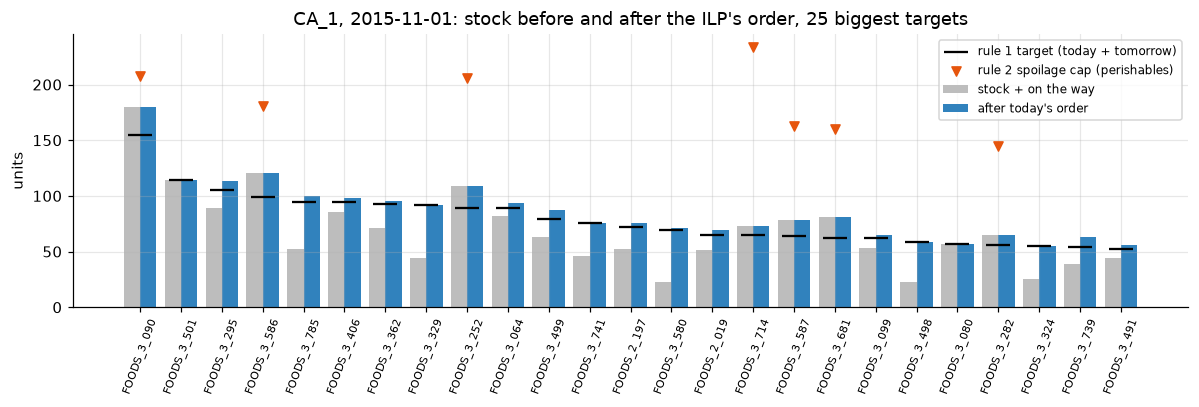

In [7]:
share = cfg["analysis"]["store_ilp"]["layers"]["service_floor"]["share"]
rows = []
for k in ks:
    p = k[1]
    it = ITEMS[p]
    line, cap = seen["line_cap"][k]
    pos = kw["position"][k]
    c = one.cartons[k]
    rows.append({"item": p, "perishable": it["shelf_life_days"] is not None, "units/carton": it["units_per_case"],
                 "stock + on way": pos, "rule 1 line": line, "rule 2 cap": cap,
                 f"floor ({share:g} x min)": share * min(line, cap), "need (line - stock)": need[k],
                 "cartons": c, "units ordered": c * it["units_per_case"],
                 "stock after order": pos + c * it["units_per_case"]})
orders = pd.DataFrame(rows).set_index("item")
print(f"{STORE}: {int((orders.cartons > 0).sum())} of {len(orders)} items ordered, "
      f"{int(orders.cartons.sum())} cartons, {orders['units ordered'].sum():,.0f} units")
display(orders.sort_values("units ordered", ascending=False).head(12).round(1))

fig, ax = plt.subplots(figsize=(11, 3.8))
top = orders.sort_values("rule 1 line", ascending=False).head(25)
x = np.arange(len(top))
ax.bar(x - 0.2, top["stock + on way"], 0.4, label="stock + on the way", color="#bdbdbd")
ax.bar(x + 0.2, top["stock after order"], 0.4, label="after today's order", color="#3182bd")
ax.scatter(x, top["rule 1 line"], marker="_", s=250, color="black", label="rule 1 target (today + tomorrow)", zorder=3)
capped = top["rule 2 cap"].replace(np.inf, np.nan)
ax.scatter(x, capped, marker="v", color="#e6550d", label="rule 2 spoilage cap (perishables)", zorder=3)
ax.set_xticks(x, top.index, rotation=70, fontsize=7)
ax.set_ylabel("units")
ax.set_title(f"{STORE}, {today}: stock before and after the ILP's order, 25 biggest targets")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
sp = pd.DataFrame(one.shadow)
print("shadow prices for", STORE, "at today's settings (value = money saved per extra unit of the limit):")
display(sp.round(3))

shadow prices for CA_1 at today's settings (value = money saved per extra unit of the limit):


,constraint,store_id,value,limit,used
0,truck,CA_1,0.0,400.000,198.000
1,space,CA_1,0.0,7702.478,1746.000
2,budget,CA_1,0.0,4795.075,2513.841


All three store limits have shadow price 0 today: they are far from full (the truck carries about half its
400 cartons, shelf space and budget have room), so the order is set by the targets, not the limits.
That matches the saved runs (section 8): truck, space and budget never bind at the current settings.

To see a non-zero shadow price, we squeeze the budget for this one store in a **copy** of the settings
(budget_factor 1.25 -> 0.45, one of the saved what-if values) and solve again:

In [9]:
tight = deepcopy(cfg)
tight["analysis"]["store_ilp"]["budget_factor"] = 0.45
squeezed = store_ilp.solve_day(tight, ks, sub(need), sub(tomorrow), cover_days, open_days,
                               position=sub(kw["position"]), cap=sub(kw["cap"]), floor_units=sub(kw["floor_units"]))
sq = pd.DataFrame(squeezed.shadow)
display(sq[sq.constraint.isin(["truck", "space", "budget"])].round(3))
floor_rows = sq[sq.constraint == "floor"]
print(f"budget_factor 0.45: {int(sum(squeezed.cartons.values()))} cartons instead of {int(sum(one.cartons.values()))}; "
      f"service floor priced on {len(floor_rows)} items (mean {floor_rows.value.mean():.2f} per unit)" if len(floor_rows)
      else "no floor rows")

,constraint,store_id,value,limit,used,item_id
0,truck,CA_1,0.000,400.000,140.000,NaN
1,space,CA_1,0.000,7702.478,1230.000,NaN
2,budget,CA_1,1.765,1726.227,1726.095,NaN


budget_factor 0.45: 140 cartons instead of 198; service floor priced on 5 items (mean 44.34 per unit)


**Reading it:** with the tight budget, one more money unit of budget would save about the amount shown in
the `budget` row today (it buys units that close a gap to the 90% floor, which costs 10 x the lost-sale
cost per unit). The floor rows show which items the 90% promise is costing money on. A manager can use
these numbers to decide whether a bigger budget, a bigger truck or more shelf space is worth paying for.

## 7. Short replay with notebook 1's forecasts

The replay (`replay/cli.py`) runs a method day by day: each morning the method decides from the stock,
the pipeline and that morning's forecast; then the order model's own `optimize.replay.execute_day` applies
the decision against the **real** sales of that day (sales, lost sales, waste of expired perishables,
deliveries) and checks that no rule is broken. Every method starts from the identical stock.

By default we run the first **7 test days** (1 to 7 Nov 2015) for `store_model` and `store_ilp`, with
the 15-second configuration and the forecasts file from notebook 1. The command-line tool takes the
forecasts path as an argument; for the output folder and the run log it reads `replay.output_dir` and
`replay.test_runs_log` from a config file, so we write a **copy** of `config.yaml` to `outputs/notebooks/`
with only those two keys changed. (Rule R9a logs every test-window run: this notebook's runs are logged in
`outputs/notebooks/test_runs.log`, so the project's own `outputs/test_runs.log` is not touched.)

Set `FULL_RUN = True` for all 8 weeks (56 days). Measured on the laptop, the 7-day run takes 40 s to
1.5 minutes depending on machine load (store_model 8 to 33 s, store_ilp 31 to 60 s), so the full run takes
roughly 6 to 12 minutes, most of it store_ilp (the saved 8-week core run took 115 s for store_model and
251 s for store_ilp; the holdout runs with the layers on took 5.6 to 8 minutes for store_ilp over 49 days).

In [10]:
FULL_RUN = False

from replay.cli import main as replay_main

run_name = "replay_full" if FULL_RUN else "replay_short"
nb_cfg = yaml.safe_load(Path("config.yaml").read_text())
nb_cfg["replay"]["output_dir"] = OUT.as_posix()                          # outputs/notebooks
nb_cfg["replay"]["test_runs_log"] = (OUT / "test_runs.log").as_posix()   # outputs/notebooks/test_runs.log
nb_cfg_path = OUT / "replay_config_notebook.yaml"
nb_cfg_path.write_text(yaml.safe_dump(nb_cfg, sort_keys=False))

run_dir = OUT / run_name
if run_dir.exists():                    # the CLI refuses an existing run folder; this one is ours to replace
    assert run_dir.resolve().parent == OUT.resolve()
    shutil.rmtree(run_dir)

args = ["--profile", "full", "--config", "configs/validation_fast.yaml", "--replay-config", str(nb_cfg_path),
        "--forecast-file", str(FC_PATH), "--methods", "store_model,store_ilp", "--run-name", run_name]
if not FULL_RUN:
    args += ["--end-date", str((pd.Timestamp(cfg["data"]["windows"]["test_start"]) + pd.Timedelta(days=6)).date())]
t0 = time.time()
replay_main(args)
print(f"replay finished in {time.time() - t0:.0f} s -> {run_dir}")

--- store_model ---


store_model: fill 0.96343, lost 2447.20, cost 119312.82, 8.5s, rules passed True


--- store_ilp ---


store_ilp: fill 0.96879, lost 2088.33, cost 120946.09, 34.2s, rules passed True


method                       store_model      store_ilp
fill_rate                       0.963426       0.968789
stockout_days                        269            221
lost_units                   2447.202536     2088.33037
waste_units                  1673.109784    1824.578394
avg_stock_value             34539.290074   34975.644231
avg_store_stock_value       34539.290074   34975.644231
avg_warehouse_stock_value           None           None
days_of_stock                   2.515472       2.536427
turnover                      163.673558     162.691084
total_cost                 119312.824636  120946.091703
net_cost                   116422.352558  117440.580552
lost_sales_penalty           6526.741013    5272.596739
orders                              4398           4385
trucks                                70             70
supplier_order_lines                   0              0
supplier_units                       0.0            0.0
service_met_share                   0.86       0

In [11]:
res = pd.read_csv(run_dir / "results_table.csv").set_index("method")
res["net_cost_plus_penalty"] = res.net_cost + res.lost_sales_penalty
show = ["fill_rate", "lost_units", "waste_units", "avg_store_stock_value", "net_cost", "lost_sales_penalty",
        "net_cost_plus_penalty", "orders", "trucks", "n_vars", "n_int", "solve_seconds_total", "wall_seconds"]
display(res[show].T.round(3))

kp = json.loads((run_dir / "kpis.json").read_text())
for m in res.index:
    print(f"{m}: all rule checks passed {kp[m]['rules']['passed']}, independent audit "
          f"{kp[m].get('independent_audit', {}).get('passed', 'n/a')}")
sp_short = pd.read_csv(run_dir / "store_ilp" / "shadow_prices.csv")
print("\nshadow price rows in this run (rows with value > 0 / all rows):")
print(sp_short.assign(binding=sp_short.value > 0).groupby("constraint").binding.agg(["sum", "size"]))

method,store_model,store_ilp
fill_rate,0.963,0.969
lost_units,2447.203,2088.330
waste_units,1673.110,1824.578
avg_store_stock_value,34539.290,34975.644
net_cost,116422.353,117440.581
lost_sales_penalty,6526.741,5272.597
net_cost_plus_penalty,122949.094,122713.177
orders,4398.000,4385.000
trucks,70.000,70.000
n_vars,NaN,6010.000


store_model: all rule checks passed True, independent audit True
store_ilp: all rule checks passed True, independent audit True

shadow price rows in this run (rows with value > 0 / all rows):
            sum  size
constraint           
budget        0    70
floor       104   104
space         0    70
truck         0    70


A 7-day run is a smoke test, not a result: the start stock (3 days of average sales) still shapes the
first week. The results that count are the 8-week runs and the holdout blocks below.

## 8. Results from the saved runs

What the saved files on this laptop contain (checked from each run's `compiled_config.yaml`):

| period | folder | methods | store_ilp layers |
|---|---|---|---|
| test window, 8 weeks (1 Nov to 26 Dec 2015) | `outputs/replay/store_ilp_2026-11-02` | `store_model`, `store_ilp` | **core only (no layers)** |
| test window, 8 weeks (optional, older run, used if present) | `outputs/replay/store_only_2day_2026-11-02` | habit (`last_week`), `topup_avg`, `topup_forecast`, `store_model` | - |
| holdout block 1 (27 Dec 2015 to 13 Feb 2016) | `outputs/replay_holdout/holdout_block1` | all 5 | service floor + spoilage cap **on** |
| holdout block 2 (14 Feb to 2 Apr 2016) | `outputs/replay_holdout/holdout_block2` | all 5 | service floor + spoilage cap **on** |
| test-window what-ifs | `outputs/replay/whatif_store_ilp_2026-11-02` | `store_ilp` | core only (no layers) |

**The 8-week test-window run with the layers on** (the final main model) was done in a cloud copy of the
project on identical data and forecasts; its output files are not on this laptop, so its numbers come from
`HANDOFF.md` (fill / lost units / waste units / store stock value / net cost + penalty):

| store_ilp version (test window, 8 weeks) | fill | lost | waste | stock value | net cost + penalty |
|---|---|---|---|---|---|
| core (reproduces the laptop file) | 94.87% | 26,208 | 8,043 | 35,279 | 934,088 |
| + service floor | 95.63% | 22,318 | 11,680 | 35,797 | 935,257 |
| + spoilage cap | 94.44% | 28,400 | 6,568 | 35,226 | 934,465 |
| **+ floor + spoilage cap (main model)** | **94.96%** | **25,727** | **7,015** | **35,663** | **932,094** |
| + stock cap (layer 1, dropped) | 94.47% | 28,243 | 6,809 | 33,444 | 934,553 |

The three simple rules on the same 8 test weeks (run `store_only_2day_2026-11-02`, from `HANDOFF.md`; the
folder may be archived): fill habit 84.1% / top-up average 95.2% / top-up forecast 97.9%; waste 19.9k /
68.0k / 73.9k; net cost + penalty 1,015k / 1,024k / 1,012k.

The holdout blocks were run once each with the frozen code and settings (block 3 is still sealed).
The simple rules there are: **habit** (`last_week`: order what sold on the same day last week),
**top-up average** (`topup_avg`: 28-day average + z x spread) and **top-up forecast** (`topup_forecast`:
the product's service line, q80/q90/q95, from the same forecasts).

**KPIs.** *Fill rate* = units sold / units demanded, open days only (higher is better). *Waste* = units thrown away
(perishables past their shelf life). *Net cost* = cash spent (purchases + trucks + order lines + holding + disposal)
minus the change in the value of stock on hand and on the way (at buy cost), so stock left over at the end is not
counted as a cost. *Lost-sale penalty* = 1.5 x price per unit of unmet demand.
**Net cost + penalty** is the single number the order model minimises in spirit: lower is better.

In [12]:
def load_table(folder, rename=None, keep=None):
    t = pd.read_csv(Path(folder) / "results_table.csv")
    if keep:
        t = t[t.method.isin(keep)]
    if rename:
        t["method"] = t.method.replace(rename)
    t["net_cost_plus_penalty"] = t.net_cost + t.lost_sales_penalty
    return t

# test window: store_model + store_ilp (core) are always here; the 3 simple rules come from the older run
# outputs/replay/store_only_2day_2026-11-02 (same data, forecasts and start), used only if that folder exists
test = load_table("outputs/replay/store_ilp_2026-11-02", rename={"store_ilp": "store_ilp (core)"})
SIMPLE_TEST = Path("outputs/replay/store_only_2day_2026-11-02")
if (SIMPLE_TEST / "results_table.csv").exists():
    simple = load_table(SIMPLE_TEST)
    assert np.isclose(simple.loc[simple.method == "store_model", "fill_rate"].iloc[0],
                      test.loc[test.method == "store_model", "fill_rate"].iloc[0])     # the same store_model run
    test = pd.concat([simple[simple.method != "store_model"], test], ignore_index=True)
else:
    print(f"NOTE: {SIMPLE_TEST} is not in this folder (it may have been archived), so the test-window rows show store_model and "
          "store_ilp only; the simple rules' test-window numbers are in the markdown table above.")
b1 = load_table("outputs/replay_holdout/holdout_block1")
b2 = load_table("outputs/replay_holdout/holdout_block2")

PERIODS = {"test window (8 wk)": test, "holdout block 1": b1, "holdout block 2": b2}
SIMPLE = ["last_week", "topup_avg", "topup_forecast"]
summary = []
for name, t in PERIODS.items():
    has_simple = t.method.isin(SIMPLE).any()
    best_simple = t[t.method.isin(SIMPLE)].net_cost_plus_penalty.min() if has_simple else np.nan
    for r in t.itertuples():
        summary.append({"period": name, "method": r.method, "fill %": 100 * r.fill_rate, "lost units": r.lost_units,
                        "waste units": r.waste_units, "store stock value": r.avg_store_stock_value,
                        "net cost + penalty": r.net_cost_plus_penalty,
                        "vs best simple rule %": 100 * (r.net_cost_plus_penalty / best_simple - 1)})
summary = pd.DataFrame(summary)
summary.round(2)

,period,method,fill %,lost units,waste units,store stock value,net cost + penalty,vs best simple rule %
0,test window (8 wk),last_week,84.06,81425.77,19907.77,18062.34,1015406.38,0.30
1,test window (8 wk),topup_avg,95.24,24329.65,67996.72,28322.80,1024171.61,1.17
2,test window (8 wk),topup_forecast,97.92,10608.25,73861.33,33844.75,1012368.38,0.00
3,test window (8 wk),store_model,94.07,30282.23,6841.59,35240.10,937832.13,-7.36
4,test window (8 wk),store_ilp (core),94.87,26208.44,8042.92,35279.24,934087.72,-7.73
5,holdout block 1,last_week,82.44,84345.22,13671.52,14597.26,927707.42,2.85
6,holdout block 1,topup_avg,94.11,28279.30,35578.63,25416.81,902041.61,0.00
7,holdout block 1,topup_forecast,97.80,10571.64,70809.05,31374.33,926141.51,2.67
8,holdout block 1,store_model,93.37,31826.83,5352.38,32478.31,861126.44,-4.54
9,holdout block 1,store_ilp,94.14,28140.35,4468.86,32916.32,855094.51,-5.20


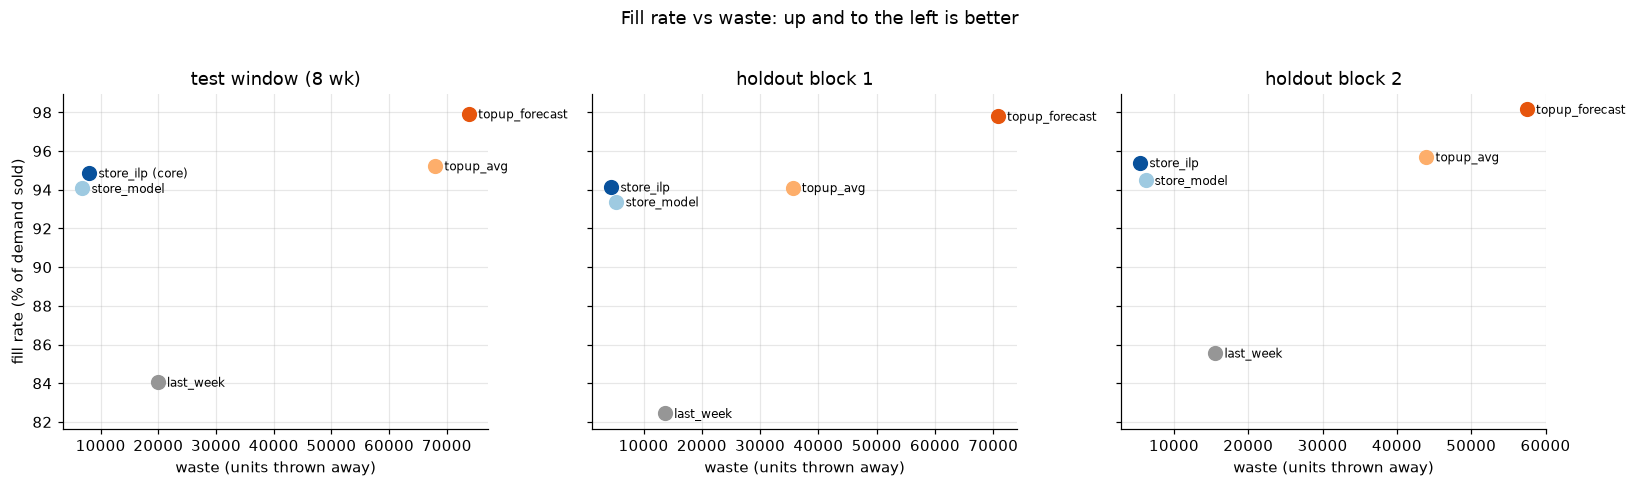

In [13]:
COLORS = {"last_week": "#969696", "topup_avg": "#fdae6b", "topup_forecast": "#e6550d", "store_model": "#9ecae1",
          "store_ilp": "#08519c", "store_ilp (core)": "#08519c"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, (name, t) in zip(axes, PERIODS.items()):
    for r in t.itertuples():
        ax.scatter(r.waste_units, 100 * r.fill_rate, s=80, color=COLORS[r.method], zorder=3)
        ax.annotate(r.method, (r.waste_units, 100 * r.fill_rate), textcoords="offset points", xytext=(6, -3), fontsize=8)
    ax.set_title(name)
    ax.set_xlabel("waste (units thrown away)")
axes[0].set_ylabel("fill rate (% of demand sold)")
fig.suptitle("Fill rate vs waste: up and to the left is better", y=1.02)
plt.tight_layout()
plt.show()

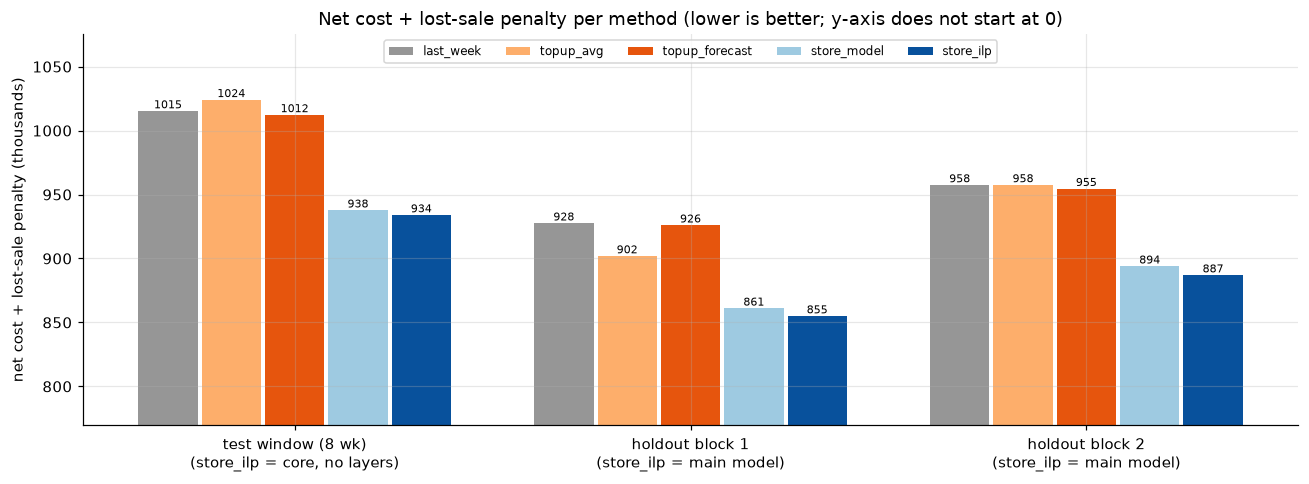

test window (8 wk): store_ilp (core) -7.7% vs the best simple rule, fill 94.87%, waste 8,043
holdout block 1: store_ilp -5.2% vs the best simple rule, fill 94.14%, waste 4,469
holdout block 2: store_ilp -7.1% vs the best simple rule, fill 95.40%, waste 5,465


In [14]:
methods = ["last_week", "topup_avg", "topup_forecast", "store_model", "store_ilp"]
fig, ax = plt.subplots(figsize=(12, 4.5))
w = 0.16
for i, m in enumerate(methods):
    vals, xs = [], []
    for j, (name, t) in enumerate(PERIODS.items()):
        row = t[t.method.str.split(" ").str[0] == m]       # "store_ilp (core)" counts as store_ilp
        if len(row):
            xs.append(j + (i - 2) * w)
            vals.append(row.net_cost_plus_penalty.iloc[0] / 1000)
    b = ax.bar(xs, vals, w - 0.01, color=COLORS[m], label=m)
    ax.bar_label(b, fmt="%.0f", fontsize=7)
ax.set_xticks(range(len(PERIODS)), [f"{k}" + ("\n(store_ilp = core, no layers)" if k.startswith("test") else "\n(store_ilp = main model)")
                                     for k in PERIODS])
ax.set_ylabel("net cost + lost-sale penalty (thousands)")
lo = min(t.net_cost_plus_penalty.min() for t in PERIODS.values()) / 1000
ax.set_ylim(lo * 0.9, None)
ax.set_title("Net cost + lost-sale penalty per method (lower is better; y-axis does not start at 0)")
ax.legend(fontsize=8, ncol=5, loc="upper center")
plt.tight_layout()
plt.show()

for name, t in PERIODS.items():
    r = summary[(summary.period == name) & summary.method.str.startswith("store_ilp")].iloc[0]
    vs = (f"{r['vs best simple rule %']:+.1f}% vs the best simple rule" if pd.notna(r['vs best simple rule %'])
          else "(simple rules not loaded for this period)")
    print(f"{name}: {r.method} {vs}, fill {r['fill %']:.2f}%, waste {r['waste units']:,.0f}")

### Shadow prices in the holdout runs

Each holdout run saved `store_ilp/shadow_prices.csv`: one row per store-day for each of truck, space and
budget (value 0 when the limit has slack), plus one row per store-item-day where the service floor or the
spoilage cap had a price.

,block,constraint,rows,binding,mean_when_binding,max_value,unit
0,block 1,budget,490,0,0.00,0.00,store-days
1,block 1,floor,1574,1574,21.19,74.70,store-item-days
2,block 1,space,490,0,0.00,0.00,store-days
3,block 1,spoil,11,11,2.00,2.25,store-item-days
4,block 1,truck,490,0,0.00,0.00,store-days
5,block 2,budget,490,0,0.00,0.00,store-days
6,block 2,floor,1352,1352,22.53,74.70,store-item-days
7,block 2,space,490,0,0.00,0.00,store-days
8,block 2,spoil,2,2,3.51,6.72,store-item-days
9,block 2,truck,490,0,0.00,0.00,store-days


service-floor rows on perishable items: 92% (perishables are 20 of 120 items)


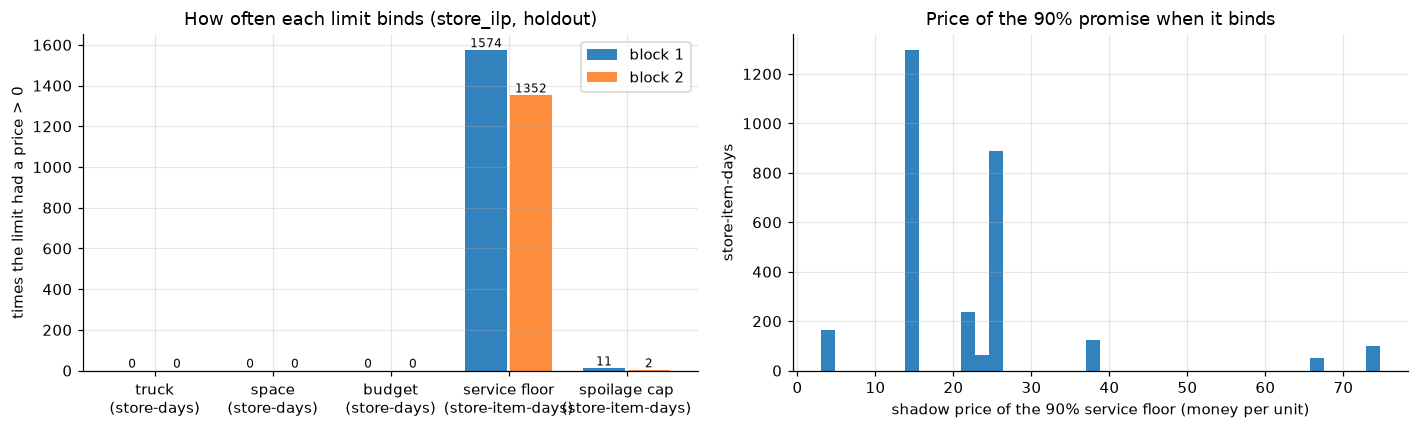

In [15]:
shadow = []
for b in (1, 2):
    s = pd.read_csv(f"outputs/replay_holdout/holdout_block{b}/store_ilp/shadow_prices.csv")
    s["block"] = f"block {b}"
    shadow.append(s)
shadow = pd.concat(shadow, ignore_index=True)
shadow["binding"] = shadow.value > 0
sp_sum = (shadow.groupby(["block", "constraint"])
          .agg(rows=("value", "size"), binding=("binding", "sum"),
               mean_when_binding=("value", lambda v: v[v > 0].mean() if (v > 0).any() else 0.0),
               max_value=("value", "max"))
          .reset_index())
sp_sum["unit"] = sp_sum.constraint.map({"truck": "store-days", "space": "store-days", "budget": "store-days",
                                        "floor": "store-item-days", "spoil": "store-item-days"})
display(sp_sum.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
order = ["truck", "space", "budget", "floor", "spoil"]
w = 0.38
for i, blk in enumerate(["block 1", "block 2"]):
    d = sp_sum[sp_sum.block == blk].set_index("constraint").reindex(order)
    b = ax.bar(np.arange(len(order)) + (i - 0.5) * w, d.binding.fillna(0), w - 0.02, label=blk,
               color=["#3182bd", "#fd8d3c"][i])
    ax.bar_label(b, fmt="%d", fontsize=8)
ax.set_xticks(range(len(order)), ["truck\n(store-days)", "space\n(store-days)", "budget\n(store-days)",
                                  "service floor\n(store-item-days)", "spoilage cap\n(store-item-days)"])
ax.set_ylabel("times the limit had a price > 0")
ax.set_title("How often each limit binds (store_ilp, holdout)")
ax.legend()
ax = axes[1]
fl = shadow[(shadow.constraint == "floor") & shadow.binding]
print(f"service-floor rows on perishable items: {fl.item_id.map(lambda p: ITEMS[p]['shelf_life_days'] is not None).mean():.0%} "
      f"(perishables are {sum(it['shelf_life_days'] is not None for it in ITEMS.values())} of {len(ITEMS)} items)")
ax.hist(fl.value, bins=40, color="#3182bd")
ax.set_xlabel("shadow price of the 90% service floor (money per unit)")
ax.set_ylabel("store-item-days")
ax.set_title("Price of the 90% promise when it binds")
plt.tight_layout()
plt.show()

**Reading it:** at the current settings the truck, shelf-space and budget limits never bind (490 store-days
per block, all 0), so they cost nothing; the orders are set by the targets. The only priced constraints
are the per-item layers: the 90% service floor binds on 1,574 / 1,352 store-item-days (days where the
cost-based choice of cartons alone would leave the item below 90% of its target, so the floor forces an
extra carton in; its shadow price is what that promise costs per unit), and the spoilage cap on a handful.

### What-ifs: when do the limits start to matter?

`analysis/whatif.py` re-ran the 8-week test window for `store_ilp` (core, no layers) with one setting changed
at a time. These runs are for sensitivity only and were never used to choose settings.

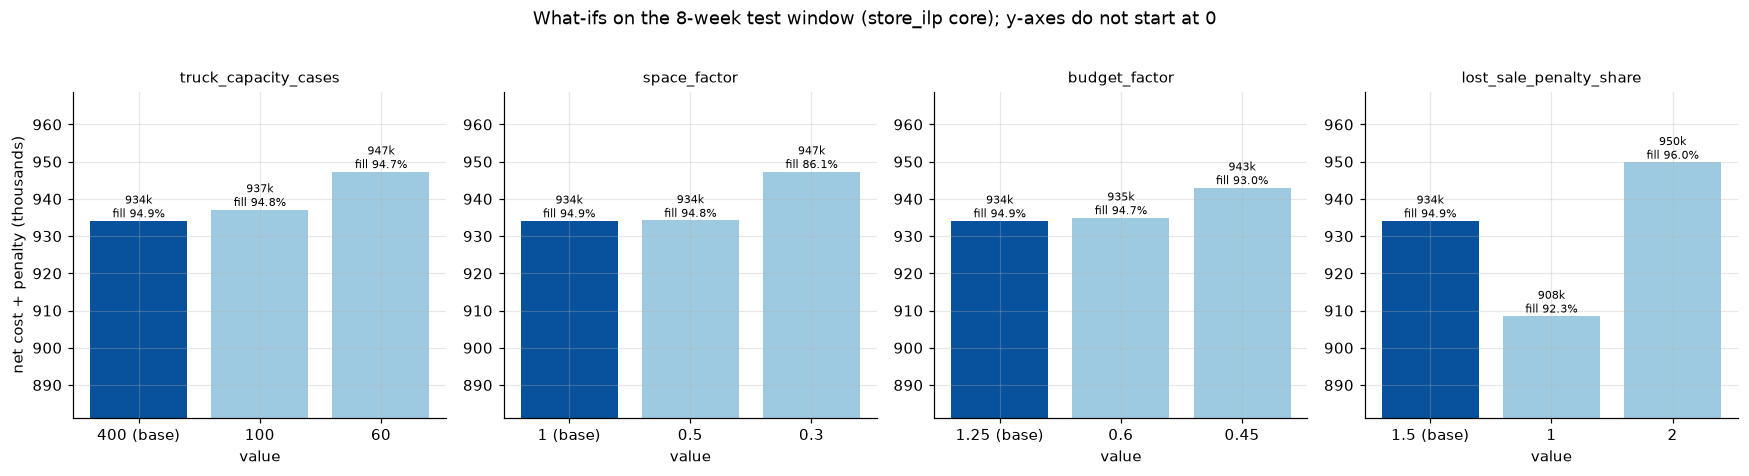

,param,value,fill_rate,waste_units,net_cost_plus_penalty,shadow_truck_binding_store_days,shadow_space_binding_store_days,shadow_budget_binding_store_days,shadow_space_mean,shadow_budget_mean
0,order_model.truck_capacity_cases,400.00,0.9487,8042.9238,934087.7198,0,0,0,0.0000,0.0000
1,order_model.truck_capacity_cases,100.00,0.9482,8037.9238,937121.4635,0,0,0,0.0000,0.0000
2,order_model.truck_capacity_cases,60.00,0.9475,7971.3510,947292.0080,1,0,0,0.0000,0.0000
3,analysis.store_ilp.space_factor,1.00,0.9487,8042.9238,934087.7198,0,0,0,0.0000,0.0000
4,analysis.store_ilp.space_factor,0.50,0.9477,8042.4265,934199.6224,0,2,0,0.0011,0.0000
5,analysis.store_ilp.space_factor,0.30,0.8605,5916.0939,947309.8894,0,318,0,0.9501,0.0000
6,analysis.store_ilp.budget_factor,1.25,0.9487,8042.9238,934087.7198,0,0,0,0.0000,0.0000
7,analysis.store_ilp.budget_factor,0.60,0.9472,8036.1490,934915.7253,0,0,12,0.0000,0.0385
8,analysis.store_ilp.budget_factor,0.45,0.9303,6880.7658,942989.8459,0,0,156,0.0000,0.5005
9,order_model.lost_sale_penalty_share,1.50,0.9487,8042.9238,934087.7198,0,0,0,0.0000,0.0000


In [16]:
wf = pd.read_csv("outputs/replay/whatif_store_ilp_2026-11-02/whatif.csv")
params = list(dict.fromkeys(wf.param))
fig, axes = plt.subplots(1, len(params), figsize=(16, 4.2))
for ax, p in zip(axes, params):
    d = wf[wf.param == p]
    labels = [f"{v:g}" + (" (base)" if i == 0 else "") for i, v in enumerate(d.value)]
    b = ax.bar(labels, d.net_cost_plus_penalty / 1000, color=["#08519c"] + ["#9ecae1"] * (len(d) - 1))
    ax.bar_label(b, labels=[f"{x/1000:.0f}k\nfill {f*100:.1f}%" for x, f in zip(d.net_cost_plus_penalty, d.fill_rate)], fontsize=7)
    ax.set_ylim(wf.net_cost_plus_penalty.min() / 1000 * 0.97, wf.net_cost_plus_penalty.max() / 1000 * 1.02)
    ax.set_title(p.split(".")[-1], fontsize=10)
    ax.set_xlabel("value")
axes[0].set_ylabel("net cost + penalty (thousands)")
fig.suptitle("What-ifs on the 8-week test window (store_ilp core); y-axes do not start at 0", y=1.02)
plt.tight_layout()
plt.show()

cols = ["param", "value", "fill_rate", "waste_units", "net_cost_plus_penalty",
        "shadow_truck_binding_store_days", "shadow_space_binding_store_days", "shadow_budget_binding_store_days",
        "shadow_space_mean", "shadow_budget_mean"]
wf[cols].round(4)

**Reading the what-ifs:**
- Trucks: even at 60 cartons per truck (from 400) the cost rises only about 1.4%; the truck limit priced on 1 store-day.
- Shelf space: halving it changes almost nothing; at 30% of the space, fill drops to 86% and the space
  shadow price is about 0.95 on 318 store-days: shelf space is now the bottleneck.
- Budget: at 0.6 x it binds on only 12 store-days; at 0.45 x on 156 (shadow price about 0.50), fill 93%.
- Lost-sale penalty share 1.0 / 2.0 moves fill to 92.3% / 96.0% and waste to 5.5k / 10.1k. Its
  "net cost + penalty" uses that run's own penalty share, so those two rows are not comparable with the rest.

## Summary

- The order model is a **newsvendor target** (cost-based stock level, spoilage cap) turned into **whole
  cartons by a small ILP per store per day**, with trucks, shelf space and budget as limits, a soft 90%
  service floor and a hard spoilage cap.
- **Shadow prices** come from fixing the integer decisions and re-solving the LP. At today's settings the
  store limits cost nothing; they only start to cost when cut hard (space x 0.3, budget x 0.45).
- On the two holdout blocks run so far, `store_ilp` has the lowest net cost + penalty of all methods
  (5.2% and 7.1% below the best simple rule) with a fill rate of 94.1% and 95.4% and the lowest waste.